<a href="https://colab.research.google.com/github/xsadaya/Dig.-Game-Ownership-Analysis/blob/main/Milestone_2_Game_Data_Collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests

url= "https://project-3b50d.vercel.app/catalog?page=1"

response= requests.get(url)

print("status code:", response.status_code)
print("content type:", response.headers.get("content-type"))

status code: 200
content type: text/html; charset=utf-8


In [ ]:
print(response.text[:500])

<!DOCTYPE html><html lang="en" class="playfair_display_3243ad1c-module___RjVwq__variable atkinson_hyperlegible_bec90635-module__nejDBq__variable"><head><meta charSet="utf-8"/><meta name="viewport" content="width=device-width, initial-scale=1"/><link rel="stylesheet" href="/_next/static/chunks/16re-87i0-vxm.css" data-precedence="next"/><link rel="preload" as="script" fetchPriority="low" href="/_next/static/chunks/186c.u8l76ivb.js"/><script src="/_next/static/chunks/0k8fcq_tsf70-.js" async=""></sc


In [ ]:
# Game found in HTML?

html = response.text

game_title = "!Peace Phantom 2!"

if game_title in html:
    print("Game found in HTML!")
else:
    print("Game not found in HTML.")


Game found in HTML!


In [ ]:

position = html.find("!Peace Phantom 2!")

print("Position:", position)

print(html[position-200:position+300])


Position: 9690
:9px;margin-bottom:6px;padding-bottom:4px">STE · 2018 · 89658</div><div class="cover has-img" style="aspect-ratio:3/4"><img src="https://images.igdb.com/igdb/image/upload/t_cover_big/co916i.jpg" alt="!Peace Phantom 2! cover" width="264" height="374" loading="lazy" decoding="async"/></div><div class="font-serif" style="font-weight:600;font-size:13px;margin-top:8px;line-height:1.2">!Peace Phantom 2!</div><div class="font-serif muted" style="font-size:11px;margin-top:2px">2018<!-- --> · <!-- -->arm


In [ ]:

from bs4 import BeautifulSoup

soup = BeautifulSoup(html, "html.parser")

game = soup.find(string=lambda text: text and "!Peace Phantom 2!" in text)

print(game)
print(game.parent.name)


!Peace Phantom 2!
div


In [ ]:

title_tag = game.parent

print(title_tag.prettify())


<div class="font-serif" style="font-weight:600;font-size:13px;margin-top:8px;line-height:1.2">
 !Peace Phantom 2!
</div>



In [ ]:

titles = soup.select("div.font-serif")

print("Elements found:", len(titles))

for title in titles[:10]:
    print(title.get_text(strip=True))

Elements found: 49
A personal, non-commercial project. Not affiliated with IGDB, RAWG, or any publisher or storefront; game metadata and cover art belong to their owners.
_Prism
2016·Unknown
!Peace Phantom 2!
2018·armogames
.Atorb.
2016·Unknown
.Hack//Sign SK Telecom
2004·Bandai Namco Entertainment Korea
.Hack//Vol. 1 LG-Telecom


In [ ]:
# Contracting game titles

game_titles = []

for tag in soup.select("div.font-serif"):
    style = tag.get("style", "")

    if "font-weight:600" in style:
        game_titles.append(tag.get_text(strip=True))

print("Game titles found:", len(game_titles))

for title in game_titles:
    print(title)


Game titles found: 24
_Prism
!Peace Phantom 2!
.Atorb.
.Hack//Sign SK Telecom
.Hack//Vol. 1 LG-Telecom
&0
#Have A Sticker
#WarGames
1 For Yes, 0 For No
1 vs. 100
1-Bit Return
1Dreamboy 2
3 Heroes: Crystal Soul
3 Kings
3-2-1, Rattle Battle!
3-D Hunting 2010
3-pun Tenkatouitsu: Bakumatsu Quiz-hen
3-pun Tenkatouitsu: Higashinippon Sengoku Quiz-hen
3, 2, 1... WordsUp!
3,2,1...WordsUp!
3D Chess Black and White
3D Classics: Excitebike
3D Classics: Kid Icarus
3D Classics: Kirby's Adventure


In [ ]:

import pandas as pd

df = pd.DataFrame(game_titles, columns=["Game Title"])

print(df.head())
print("Total records:", len(df))

df.to_csv("game_titles_page1.csv", index=False)


                 Game Title
0                    _Prism
1         !Peace Phantom 2!
2                   .Atorb.
3    .Hack//Sign SK Telecom
4  .Hack//Vol. 1 LG-Telecom
Total records: 24


In [ ]:

url2 = "https://project-3b50d.vercel.app/catalog?page=2"

response2 = requests.get(url2, timeout=20)

soup2 = BeautifulSoup(response2.text, "html.parser")

game_titles2 = []

for tag in soup2.select("div.font-serif"):
    style = tag.get("style", "")

    if "font-weight:600" in style:
        game_titles2.append(tag.get_text(strip=True))

print("Page 2 games found:", len(game_titles2))

for title in game_titles2[:5]:
    print(title)


Page 2 games found: 24
3D Classics: TwinBee
3D Classics: Urban Champion
3D Classics: Xevious
3D Pinball Space Attack
3D Realms Anthology


In [ ]:

def get_game_titles(page):
    url = f"https://project-3b50d.vercel.app/catalog?page={page}"

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    titles = []

    for tag in soup.select("div.font-serif"):
        style = tag.get("style", "")

        if "font-weight:600" in style:
            titles.append(tag.get_text(strip=True))

    return titles


# Test the function on page 3
page3_titles = get_game_titles(3)

print("Page 3 games found:", len(page3_titles))
print(page3_titles[:5])


Page 3 games found: 24
['007 Legends', '7he Code', '8 Ball Hero', '8 Bit Pop Quiz', '8 Queens']


In [ ]:

import time

all_games = []

for page in range(1, 6):
    titles = get_game_titles(page)

    print(f"Page {page}: {len(titles)} games")

    for title in titles:
        all_games.append({
            "title": title,
            "page": page
        })

    time.sleep(2)

print("Total games collected:", len(all_games))


Page 1: 24 games
Page 2: 24 games
Page 3: 24 games
Page 4: 24 games
Page 5: 24 games
Total games collected: 120


In [ ]:

game_tag = game.parent

print(game_tag.parent.prettify()[:3000])


<a class="indexcard" href="/record/peace-phantom-2" style="padding:10px">
 <div class="deweycall" style="font-size:9px;margin-bottom:6px;padding-bottom:4px">
  STE · 2018 · 89658
 </div>
 <div class="cover has-img" style="aspect-ratio:3/4">
  <img alt="!Peace Phantom 2! cover" decoding="async" height="374" loading="lazy" src="https://images.igdb.com/igdb/image/upload/t_cover_big/co916i.jpg" width="264"/>
 </div>
 <div class="font-serif" style="font-weight:600;font-size:13px;margin-top:8px;line-height:1.2">
  !Peace Phantom 2!
 </div>
 <div class="font-serif muted" style="font-size:11px;margin-top:2px">
  2018
  <!-- -->
  ·
  <!-- -->
  armogames
 </div>
 <div style="display:flex;gap:4px;margin-top:6px;flex-wrap:wrap">
  <span class="font-typewriter muted" style="font-size:8px;letter-spacing:0.08em">
   ADVENTURE
  </span>
  <span class="font-typewriter muted" style="font-size:8px;letter-spacing:0.08em">
   INDIE
  </span>
 </div>
</a>



In [ ]:

card = game.parent.parent

title = card.select_one("div.font-serif")

details = card.select_one("div.font-serif.muted")

genres = card.select("span.font-typewriter.muted")

link = card.get("href")

print("Title:", title.get_text(strip=True))
print("Year and publisher:", details.get_text(" ", strip=True))
print("Genres:", [g.get_text(strip=True) for g in genres])
print("Detail link:", link)


Title: !Peace Phantom 2!
Year and publisher: 2018 · armogames
Genres: ['ADVENTURE', 'INDIE']
Detail link: /record/peace-phantom-2


In [ ]:

def get_game_records(page):
    url = f"https://project-3b50d.vercel.app/catalog?page={page}"

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    records = []

    for card in soup.select("a.indexcard"):
        title_tag = card.select_one("div.font-serif")
        details_tag = card.select_one("div.font-serif.muted")
        genre_tags = card.select("span.font-typewriter.muted")

        if title_tag is None:
            continue

        title = title_tag.get_text(strip=True)

        details = (
            details_tag.get_text(" ", strip=True)
            if details_tag else ""
        )

        parts = details.split(" · ", 1)
        year = parts[0].strip() if parts else ""
        publisher = parts[1].strip() if len(parts) > 1 else ""

        genres = ", ".join(
            tag.get_text(strip=True) for tag in genre_tags
        )

        records.append({
            "title": title,
            "year": year,
            "publisher": publisher,
            "genres": genres,
            "detail_link": card.get("href", ""),
            "page": page
        })

    return records


page1_records = get_game_records(1)

df_test = pd.DataFrame(page1_records)

print("Records found:", len(df_test))
display(df_test.head())


Records found: 24


,title,year,publisher,genres,detail_link,page
0,_Prism,2016,Unknown,"PUZZLE, INDIE",/record/prism--2,1
1,!Peace Phantom 2!,2018,armogames,"ADVENTURE, INDIE",/record/peace-phantom-2,1
2,.Atorb.,2016,Unknown,"POINT-AND-CLICK, PUZZLE",/record/dot-atorb,1
3,.Hack//Sign SK Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-sign-sk-telecom,1
4,.Hack//Vol. 1 LG-Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-vol-1-lg-telecom,1


In [ ]:

print("Total records:", len(df_test))

print("\nMissing values:")
print(df_test.isna().sum())

print("\nUnknown publishers:")
print((df_test["publisher"] == "Unknown").sum())

print("\nDuplicate game links:")
print(df_test["detail_link"].duplicated().sum())

print("\nRelease years:")
print(df_test["year"].value_counts().head(10))


Total records: 24

Missing values:
title          0
year           0
publisher      0
genres         0
detail_link    0
page           0
dtype: int64

Unknown publishers:
3

Duplicate game links:
0

Release years:
year
2012    4
2016    3
2010    3
2018    3
2009    2
2004    2
2011    2
2022    1
2014    1
2017    1
Name: count, dtype: int64


In [ ]:

page2_records = get_game_records(2)

df_page2 = pd.DataFrame(page2_records)

print("Page 2 records:", len(df_page2))

display(df_page2.head())

print("\nUnknown publishers:",
      (df_page2["publisher"] == "Unknown").sum())

print("Duplicate links:",
      df_page2["detail_link"].duplicated().sum())


Page 2 records: 24


,title,year,publisher,genres,detail_link,page
0,3D Classics: TwinBee,2011,Nintendo,"SHOOTER, ARCADE",/record/3d-classics-twinbee,2
1,3D Classics: Urban Champion,2011,Nintendo,"FIGHTING, ARCADE",/record/3d-classics-urban-champion,2
2,3D Classics: Xevious,2011,Nintendo,"SHOOTER, ARCADE",/record/3d-classics-xevious,2
3,3D Pinball Space Attack,2010,TLK Games,PINBALL,/record/3d-pinball-space-attack,2
4,3D Realms Anthology,2014,Apogee Software,"SHOOTER, PLATFORM",/record/3d-realms-anthology,2



Unknown publishers: 9
Duplicate links: 0


In [ ]:

import pandas as pd

# Combine records from pages 1 and 2
combined_records = page1_records + page2_records

# Convert them into a table
df_combined = pd.DataFrame(combined_records)

# Save the table as a CSV
df_combined.to_csv("delisted_games_batch1.csv", index=False)

# Check our results
print("Total records saved:", len(df_combined))
print("Unique game links:", df_combined["detail_link"].nunique())

display(df_combined.head())


Total records saved: 48
Unique game links: 48


,title,year,publisher,genres,detail_link,page
0,_Prism,2016,Unknown,"PUZZLE, INDIE",/record/prism--2,1
1,!Peace Phantom 2!,2018,armogames,"ADVENTURE, INDIE",/record/peace-phantom-2,1
2,.Atorb.,2016,Unknown,"POINT-AND-CLICK, PUZZLE",/record/dot-atorb,1
3,.Hack//Sign SK Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-sign-sk-telecom,1
4,.Hack//Vol. 1 LG-Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-vol-1-lg-telecom,1


In [ ]:

import pandas as pd
import time
import random
from pathlib import Path

output = Path("delisted_games_full.csv")

# Resume from an existing saved CSV, if available
if output.exists():
    all_records = pd.read_csv(output).to_dict("records")
else:
    all_records = []

completed_pages = {
    int(record["page"]) for record in all_records
}

# Approximately 207 pages based on the earlier catalogue count
for page in range(1, 208):
    if page in completed_pages:
        continue

    try:
        records = get_game_records(page)

        if len(records) == 0:
            print(f"Page {page}: No records; stopping.")
            break

        if len(records) != 24 and page != 207:
            print(f"Page {page}: Unexpected count; stopping.")
            break

        all_records.extend(records)

        df_full = pd.DataFrame(all_records)
        df_full.to_csv(output, index=False)

        print(f"Page {page}: {len(records)} records saved")

        time.sleep(random.uniform(2, 4))

    except Exception as error:
        print(f"Stopped on page {page}: {error}")
        break

df_full = pd.DataFrame(all_records)

print("\nTotal records:", len(df_full))
print("Unique links:", df_full["detail_link"].nunique())
print("Pages collected:", df_full["page"].nunique())


Page 1: 24 records saved
Page 2: 24 records saved
Page 3: 24 records saved
Page 4: 24 records saved
Page 5: 24 records saved
Page 6: 24 records saved
Page 7: 24 records saved
Page 8: 24 records saved
Page 9: 24 records saved
Page 10: 24 records saved
Page 11: 24 records saved
Page 12: 24 records saved
Page 13: 24 records saved
Page 14: 24 records saved
Page 15: 24 records saved
Page 16: 24 records saved
Page 17: 24 records saved
Page 18: 24 records saved
Page 19: 24 records saved
Page 20: 24 records saved
Page 21: 24 records saved
Page 22: 24 records saved
Page 23: 24 records saved
Page 24: 24 records saved
Page 25: 24 records saved
Page 26: 24 records saved
Page 27: 24 records saved
Page 28: 24 records saved
Page 29: 24 records saved
Page 30: 24 records saved
Page 31: 24 records saved
Page 32: 24 records saved
Page 33: 24 records saved
Page 34: 24 records saved
Page 35: 24 records saved
Page 36: 24 records saved
Page 37: 24 records saved
Page 38: 24 records saved
Page 39: 24 records s

In [ ]:

import os

print("Files available:")
print(os.listdir())

print("\nIs our full dataset saved?")
print(os.path.exists("delisted_games_full.csv"))


Files available:
['.config', 'delisted_games_batch1.csv', 'delisted_games_full.csv', 'game_titles_page1.csv', 'sample_data']

Is our full dataset saved?
True


In [ ]:

import os

print("Dataset saved:", os.path.exists("delisted_games_full.csv"))


Dataset saved: True


In [ ]:

from google.colab import files

files.download("delisted_games_full.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#MILESTONE 2 - DATA CLEANING

In [ ]:
import pandas as pd

df = pd.read_csv("delisted_games_full.csv")

print("Total rows:", len(df))
print("Total columns:", len(df.columns))

display(df.head())

Total rows: 4968
Total columns: 6


,title,year,publisher,genres,detail_link,page
0,_Prism,2016,Unknown,"PUZZLE, INDIE",/record/prism--2,1
1,!Peace Phantom 2!,2018,armogames,"ADVENTURE, INDIE",/record/peace-phantom-2,1
2,.Atorb.,2016,Unknown,"POINT-AND-CLICK, PUZZLE",/record/dot-atorb,1
3,.Hack//Sign SK Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-sign-sk-telecom,1
4,.Hack//Vol. 1 LG-Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-vol-1-lg-telecom,1


In [ ]:
# Check for missing values in each column
print("Missing values by column:")
print(df.isnull().sum())

# Check how many publishers are labeled Unknown
print("\nUnknown publishers:")
print((df["publisher"] == "Unknown").sum())

Missing values by column:
title            0
year             0
publisher        0
genres         618
detail_link      0
page             0
dtype: int64

Unknown publishers:
820


In [ ]:
# Make a copy so our original data stays unchanged
df_clean = df.copy()

# Replace missing genres with "Unknown"
df_clean["genres"] = df_clean["genres"].fillna("Unknown")

# Check our results
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nTotal games remaining:", len(df_clean))

Missing values after cleaning:
title          0
year           0
publisher      0
genres         0
detail_link    0
page           0
dtype: int64

Total games remaining: 4968


In [ ]:
# Count duplicate game links
duplicates = df_clean["detail_link"].duplicated().sum()

print("Duplicate games:", duplicates)

# Check how many unique games we have
print("Unique games:", df_clean["detail_link"].nunique())

# Check total records
print("Total records:", len(df_clean))

Duplicate games: 0
Unique games: 4968
Total records: 4968


In [ ]:
# Save the cleaned dataset as a new CSV file
df_clean.to_csv("delisted_games_cleaned.csv", index=False)

# Download the cleaned dataset to your Mac
from google.colab import files

files.download("delisted_games_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

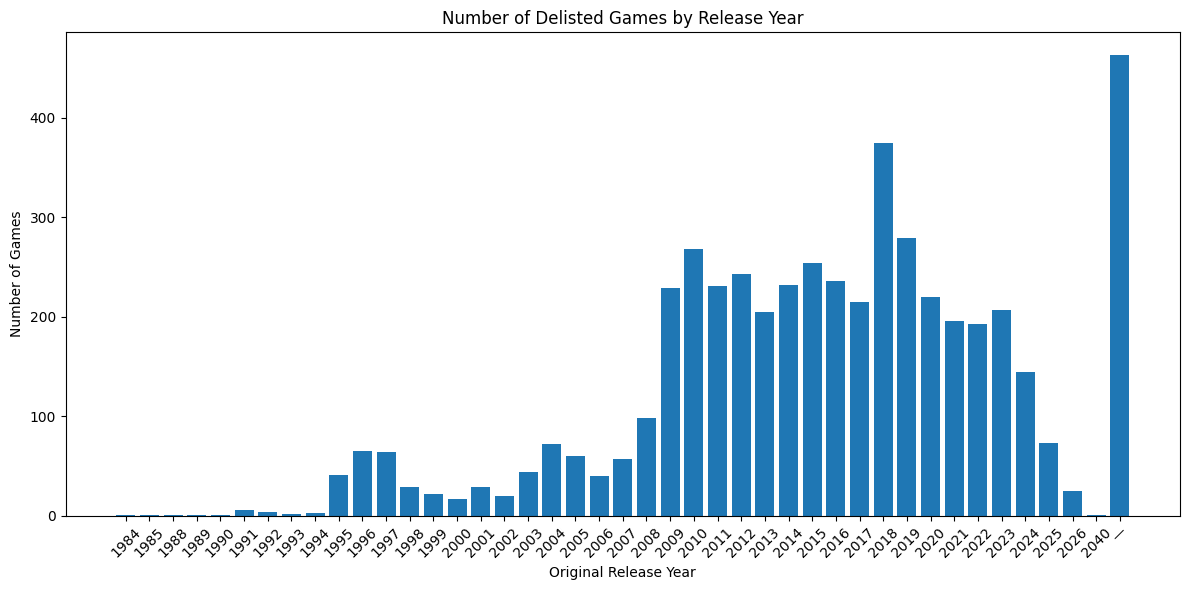

In [ ]:
import matplotlib.pyplot as plt

# Count games by their original release year
games_by_year = df_clean["year"].value_counts().sort_index()

# Create our graph
plt.figure(figsize=(12, 6))

plt.bar(games_by_year.index, games_by_year.values)

plt.title("Number of Delisted Games by Release Year")
plt.xlabel("Original Release Year")
plt.ylabel("Number of Games")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:

# Convert release years to numbers
df_clean["year"] = pd.to_numeric(df_clean["year"], errors="coerce")

# Find games with future release years
future_games = df_clean[df_clean["year"] > 2026]

print("Games with future release years:", len(future_games))

# Count games by future release year
print(future_games["year"].value_counts().sort_index())

# Display the first 10 unusual records
display(future_games.head(10))


Games with future release years: 1
year
2040.0    1
Name: count, dtype: int64


,title,year,publisher,genres,detail_link,page
4293,Star Fighters,2040.0,Orakga,"ROLE-PLAYING (RPG), STRATEGY",/record/star-fighters,179


In [ ]:
# Making sure code is connected

print("df_clean" in globals())

False


In [ ]:
import pandas as pd

df_clean = pd.read_csv("delisted_games_cleaned.csv")

print("Total games:", len(df_clean))
display(df_clean.head())

Total games: 4968


,title,year,publisher,genres,detail_link,page
0,_Prism,2016,Unknown,"PUZZLE, INDIE",/record/prism--2,1
1,!Peace Phantom 2!,2018,armogames,"ADVENTURE, INDIE",/record/peace-phantom-2,1
2,.Atorb.,2016,Unknown,"POINT-AND-CLICK, PUZZLE",/record/dot-atorb,1
3,.Hack//Sign SK Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-sign-sk-telecom,1
4,.Hack//Vol. 1 LG-Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-vol-1-lg-telecom,1


In [ ]:
# Convert release years into numbers
df_clean["year"] = pd.to_numeric(df_clean["year"], errors="coerce")

# Count unknown release years
unknown_years = df_clean["year"].isna().sum()

print("Unknown release years:", unknown_years)

# Count future release years
future_years = (df_clean["year"] > 2026).sum()

print("Future release years:", future_years)

Unknown release years: 463
Future release years: 1


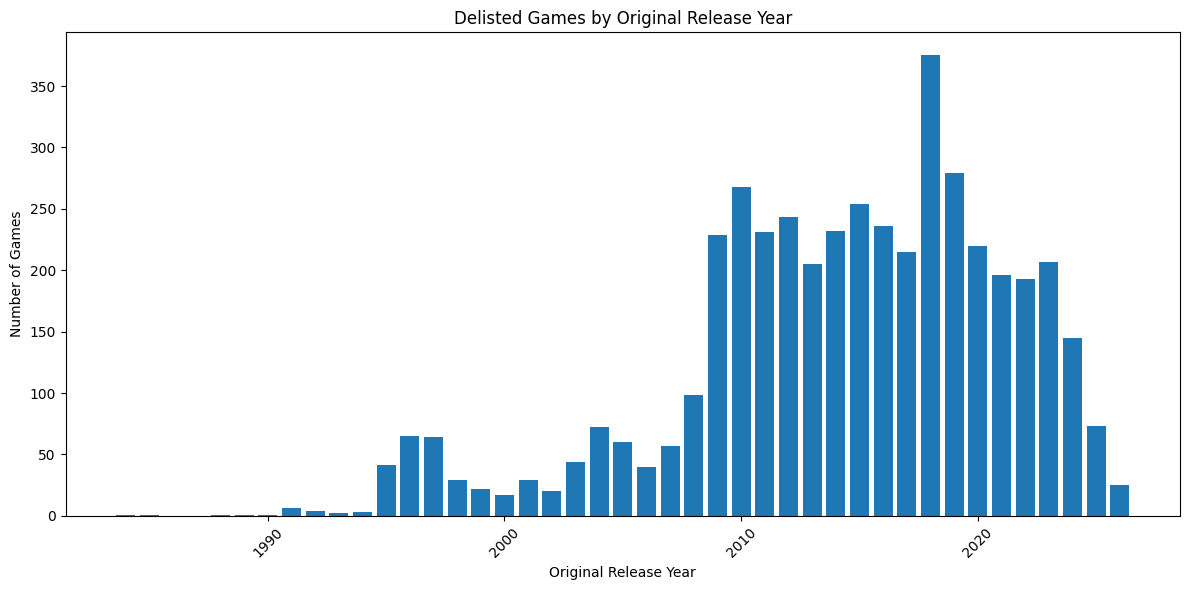

Games included in chart: 4504


In [ ]:

import matplotlib.pyplot as plt

# Keep only games with valid historical release years
df_years = df_clean[
    df_clean["year"].between(1980, 2026)
].copy()

# Count games released each year
games_by_year = df_years["year"].value_counts().sort_index()

# Create the corrected graph
plt.figure(figsize=(12, 6))
plt.bar(games_by_year.index, games_by_year.values)

plt.title("Delisted Games by Original Release Year")
plt.xlabel("Original Release Year")
plt.ylabel("Number of Games")

plt.xticks(rotation=45)
plt.tight_layout()

# Save the chart for our presentation
plt.savefig("delisted_games_by_year.png", dpi=300)

plt.show()

print("Games included in chart:", len(df_years))


In [ ]:
from google.colab import files

files.download("delisted_games_by_year.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

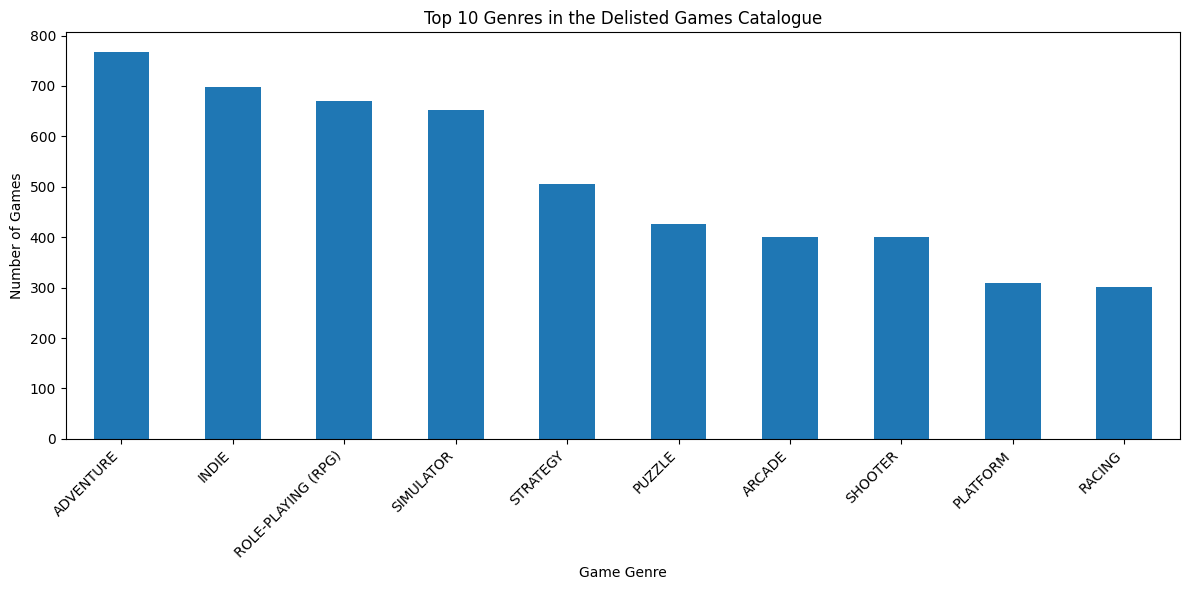

genres
ADVENTURE             768
INDIE                 697
ROLE-PLAYING (RPG)    671
SIMULATOR             653
STRATEGY              505
PUZZLE                426
ARCADE                401
SHOOTER               401
PLATFORM              310
RACING                302
Name: count, dtype: int64


In [ ]:

# Separate games that have multiple genres
genres = df_clean["genres"].dropna().str.split(", ").explode()

# Remove unknown genres
genres = genres[genres != "Unknown"]

# Count the 10 most common genres
top_genres = genres.value_counts().head(10)

# Create our chart
plt.figure(figsize=(12, 6))
top_genres.plot(kind="bar")

plt.title("Top 10 Genres in the Delisted Games Catalogue")
plt.xlabel("Game Genre")
plt.ylabel("Number of Games")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save the graph
plt.savefig("delisted_games_genres.png", dpi=300)

plt.show()

# Display exact counts
print(top_genres)
# Checking Connection

In [ ]:

print("df_clean" in globals())


False


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df_clean = pd.read_csv("delisted_games_cleaned.csv")

print("Total games loaded:", len(df_clean))
display(df_clean.head())


Total games loaded: 4968


,title,year,publisher,genres,detail_link,page
0,_Prism,2016,Unknown,"PUZZLE, INDIE",/record/prism--2,1
1,!Peace Phantom 2!,2018,armogames,"ADVENTURE, INDIE",/record/peace-phantom-2,1
2,.Atorb.,2016,Unknown,"POINT-AND-CLICK, PUZZLE",/record/dot-atorb,1
3,.Hack//Sign SK Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-sign-sk-telecom,1
4,.Hack//Vol. 1 LG-Telecom,2004,Bandai Namco Entertainment Korea,"ROLE-PLAYING (RPG), TURN-BASED STRATEGY (TBS)",/record/dot-hack-slash-slash-vol-1-lg-telecom,1


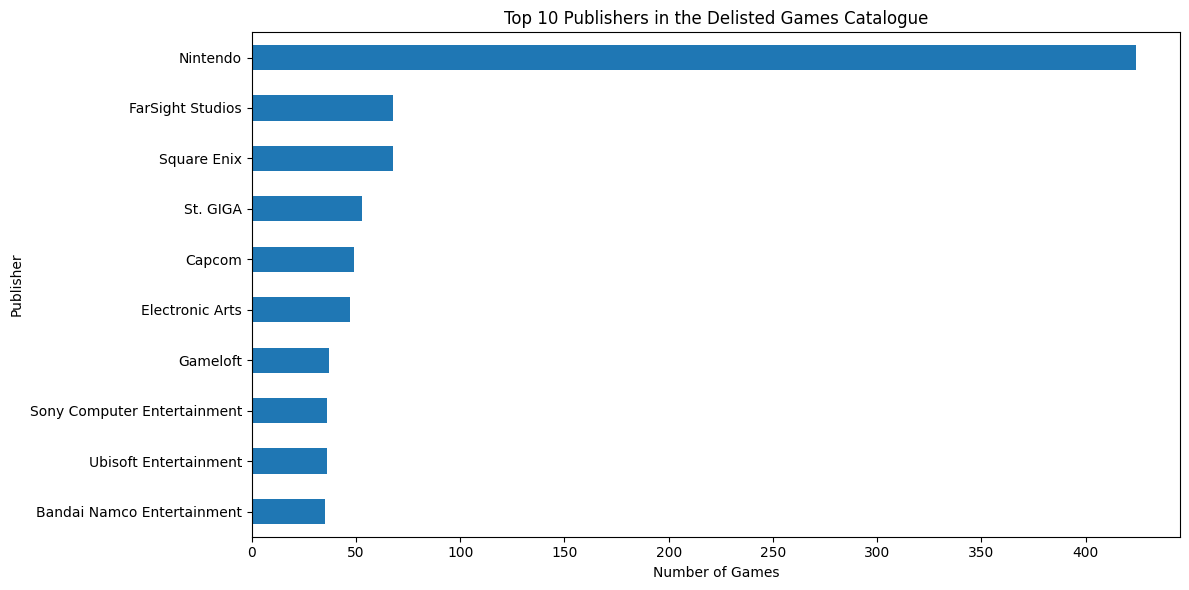

publisher
Nintendo                       424
Square Enix                     68
FarSight Studios                68
St. GIGA                        53
Capcom                          49
Electronic Arts                 47
Gameloft                        37
Ubisoft Entertainment           36
Sony Computer Entertainment     36
Bandai Namco Entertainment      35
Name: count, dtype: int64


In [ ]:

# Clean publisher names and exclude unknown values
publishers = df_clean["publisher"].fillna("Unknown").astype(str).str.strip()

known_publishers = publishers[
    (publishers.str.lower() != "unknown") &
    (publishers != "")
]

# Find the 10 most frequently listed publishers
top_publishers = known_publishers.value_counts().head(10)

# Create the chart
plt.figure(figsize=(12, 6))
top_publishers.sort_values().plot(kind="barh")

plt.title("Top 10 Publishers in the Delisted Games Catalogue")
plt.xlabel("Number of Games")
plt.ylabel("Publisher")

plt.tight_layout()
plt.savefig("delisted_games_publishers.png", dpi=300)
plt.show()

print(top_publishers)


In [ ]:

from google.colab import files

files.download("delisted_games_publishers.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Load the video game sales dataset
df_sales = pd.read_csv("/vgsales.csv")

# Verify the dataset
print("Total sales records:", len(df_sales))

# Display column names
print("\nColumns:")
print(df_sales.columns.tolist())

# Preview the first five rows
display(df_sales.head())


Total sales records: 16598

Columns:
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Restore both datasets
df_clean = pd.read_csv("delisted_games_cleaned.csv")
df_sales = pd.read_csv("vgsales.csv")

# Verify everything loaded
print("Delisted games:", len(df_clean))
print("Sales records:", len(df_sales))


Delisted games: 4968
Sales records: 16598


In [ ]:

# Standardize game titles for comparison
df_sales["title_clean"] = (
    df_sales["Name"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

df_clean["title_clean"] = (
    df_clean["title"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

# Find titles appearing in both datasets
matching_titles = (
    set(df_sales["title_clean"]) &
    set(df_clean["title_clean"])
)

# Remove empty titles
matching_titles.discard("")

# Display results
print("Matching unique game titles:", len(matching_titles))

print("\nFirst 20 matching titles:")
for title in sorted(matching_titles)[:20]:
    print(title)


Matching unique game titles: 162

First 20 matching titles:
1 vs. 100
2010 fifa world cup south africa
ace combat: assault horizon
adventure time: explore the dungeon because i don't know!
adventure time: the secret of the nameless kingdom
alice in wonderland
angry birds
angry birds star wars
ant nation
area 51
around the world in 80 days
asteroids
ballistic
batman: arkham origins
battleborn
battlefield 1942
battlefield 2
battlefield vietnam
battlefield: bad company
battleforge


In [ ]:

# Get records with matching titles
matched_sales = df_sales[
    df_sales["title_clean"].isin(matching_titles)
].copy()

matched_delisted = df_clean[
    df_clean["title_clean"].isin(matching_titles)
].copy()

# Convert release years to numbers
matched_sales["Year"] = pd.to_numeric(
    matched_sales["Year"], errors="coerce"
)

matched_delisted["year"] = pd.to_numeric(
    matched_delisted["year"], errors="coerce"
)

# Compare matching titles and release years
year_matches = matched_sales.merge(
    matched_delisted,
    on="title_clean",
    how="inner",
    suffixes=("_sales", "_delisted")
)

year_matches["year_difference"] = abs(
    year_matches["Year"] - year_matches["year"]
)

# Count exact release-year matches
exact_year_matches = year_matches[
    year_matches["year_difference"] == 0
]

print("Matching title/release-year record pairs:",
      len(exact_year_matches))

print("Unique titles with matching years:",
      exact_year_matches["title_clean"].nunique())

# Preview the results
display(
    exact_year_matches[
        ["Name", "Platform", "Year", "publisher", "year"]
    ].head(15)
)


Matching title/release-year record pairs: 190
Unique titles with matching years: 86


,Name,Platform,Year,publisher,year
2,Super Smash Bros. Brawl,Wii,2008.0,ExtraToxic,2008.0
4,Gran Turismo 5,PS3,2010.0,Sony Computer Entertainment,2010.0
6,The Sims 3,PC,2009.0,Electronic Arts,2009.0
10,Uncharted 3: Drake's Deception,PS3,2011.0,Sony Computer Entertainment,2011.0
11,Uncharted 2: Among Thieves,PS3,2009.0,Sony Computer Entertainment,2009.0
15,Super Smash Bros.,N64,1999.0,Nintendo,1999.0
18,Need for Speed: Most Wanted,PS2,2005.0,Electronic Arts,2005.0
22,Gran Turismo 6,PS3,2013.0,Sony Computer Entertainment,2013.0
23,FIFA Soccer 08,PS2,2007.0,EA Sports,2007.0
25,Killzone 2,PS3,2009.0,Sony Computer Entertainment,2009.0


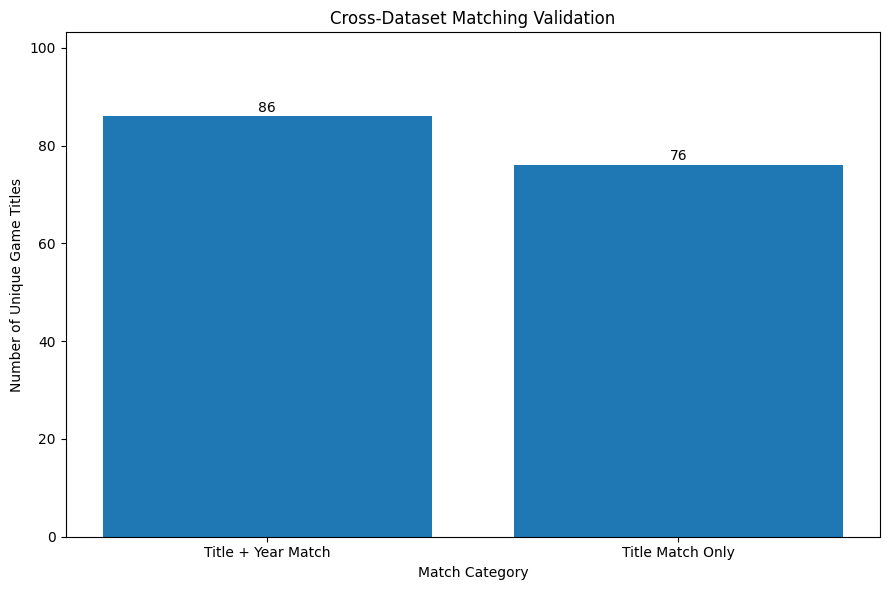

Title + year matches: 86
Title-only matches: 76


In [ ]:

# Count unique titles in each category
matched_year_titles = exact_year_matches["title_clean"].nunique()

unmatched_year_titles = (
    len(matching_titles) - matched_year_titles
)

# Prepare chart data
categories = [
    "Title + Year Match",
    "Title Match Only"
]

counts = [
    matched_year_titles,
    unmatched_year_titles
]

# Create chart
plt.figure(figsize=(9, 6))
bars = plt.bar(categories, counts)

plt.title("Cross-Dataset Matching Validation")
plt.ylabel("Number of Unique Game Titles")
plt.xlabel("Match Category")

# Add counts above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha="center"
    )

plt.ylim(0, max(counts) * 1.2)
plt.tight_layout()

plt.savefig("cross_dataset_validation.png", dpi=300)
plt.show()

print("Title + year matches:", matched_year_titles)
print("Title-only matches:", unmatched_year_titles)


In [ ]:

from google.colab import files

# Save one row per unique title with matching release years
validated_titles = (
    exact_year_matches
    .sort_values("title_clean")
    .drop_duplicates(subset=["title_clean"])
    .copy()
)

validated_titles.to_csv(
    "validated_game_matches.csv",
    index=False
)

print("Unique titles saved:", len(validated_titles))

# Download the dataset and fourth chart
files.download("validated_game_matches.csv")
files.download("cross_dataset_validation.png")


Unique titles saved: 86


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

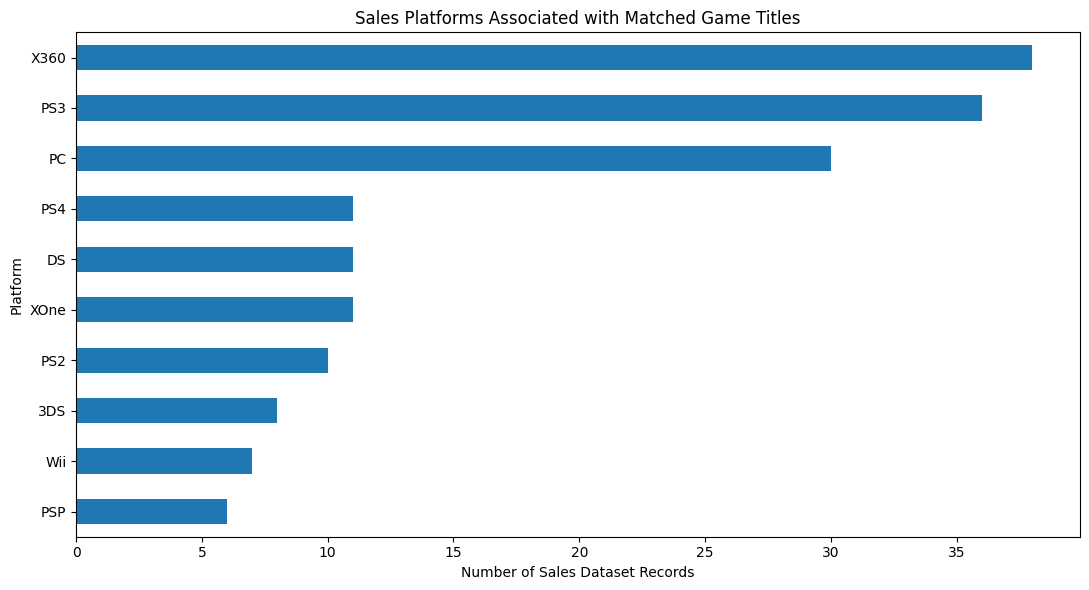

Platform
X360    38
PS3     36
PC      30
PS4     11
XOne    11
DS      11
PS2     10
3DS      8
Wii      7
PSP      6
Name: count, dtype: int64

Total matched sales records: 188


In [ ]:

# Identify unique title-and-year combinations
matched_keys = exact_year_matches[
    ["title_clean", "Year"]
].drop_duplicates()

# Match those combinations to sales records
platform_records = df_sales.merge(
    matched_keys,
    on=["title_clean", "Year"],
    how="inner"
)

# Count records by platform
platform_counts = (
    platform_records["Platform"]
    .value_counts()
    .head(10)
)

# Create visualization
plt.figure(figsize=(11, 6))

platform_counts.sort_values().plot(kind="barh")

plt.title("Sales Platforms Associated with Matched Game Titles")
plt.xlabel("Number of Sales Dataset Records")
plt.ylabel("Platform")

plt.tight_layout()
plt.savefig("matched_games_platforms.png", dpi=300)
plt.show()

print(platform_counts)
print("\nTotal matched sales records:", len(platform_records))


In [ ]:

from google.colab import files

files.download("matched_games_platforms.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Recalculate publisher counts
publishers = df_clean["publisher"].fillna("Unknown").astype(str).str.strip()

known_publishers = publishers[
    (publishers.str.lower() != "unknown") &
    (publishers != "")
]

top_publishers = known_publishers.value_counts().head(10)

print("Top 5 Publishers:")
print(top_publishers.head(5))


Top 5 Publishers:
publisher
Nintendo            424
Square Enix          68
FarSight Studios     68
St. GIGA             53
Capcom               49
Name: count, dtype: int64


In [ ]:

# Milestone 3 analysis summary

print("MILESTONE 3 — DATA ANALYSIS SUMMARY")
print("=" * 45)

print("\nDATASETS")
print("Delisted-game records:", len(df_clean))
print("Video game sales records:", len(df_sales))

print("\nCROSS-DATASET MATCHING")
print("Matching unique titles:", len(matching_titles))
print("Titles with matching release years:",
      exact_year_matches["title_clean"].nunique())

print("\nTOP 5 PUBLISHERS")
print(top_publishers.head(5))

print("\nTOP 5 PLATFORMS IN MATCHED SALES RECORDS")
print(platform_counts.head(5))

print("\nDATA QUALITY")
print("Missing/unknown publishers:",
      df_clean["publisher"].fillna("Unknown")
      .str.strip().str.lower().eq("unknown").sum())

print("Missing release years:",
      pd.to_numeric(
          df_clean["year"], errors="coerce"
      ).isna().sum())


MILESTONE 3 — DATA ANALYSIS SUMMARY

DATASETS
Delisted-game records: 4968
Video game sales records: 16598

CROSS-DATASET MATCHING
Matching unique titles: 162
Titles with matching release years: 86

TOP 5 PUBLISHERS
publisher
Nintendo            424
Square Enix          68
FarSight Studios     68
St. GIGA             53
Capcom               49
Name: count, dtype: int64

TOP 5 PLATFORMS IN MATCHED SALES RECORDS
Platform
X360    38
PS3     36
PC      30
PS4     11
XOne    11
Name: count, dtype: int64

DATA QUALITY
Missing/unknown publishers: 820
Missing release years: 463


In [ ]:

# Create a summary file
summary = f"""
MILESTONE 3 — DIGITAL GAME OWNERSHIP ANALYSIS

DATASETS
Delisted-game records: {len(df_clean)}
Video game sales records: {len(df_sales)}

CROSS-DATASET MATCHING
Matching unique titles: {len(matching_titles)}
Titles with matching release years: {exact_year_matches['title_clean'].nunique()}

TOP 5 PUBLISHERS
{top_publishers.head(5).to_string()}

TOP 5 MATCHED SALES PLATFORMS
{platform_counts.head(5).to_string()}

DATA QUALITY
Unknown publishers: 820
Missing/invalid release years: 463

LIMITATIONS
- Title and year matches do not verify platform-specific delisting.
- The datasets do not establish physical versus digital ownership.
- Counts from a delisted-games catalogue are not delisting rates.
"""

with open("milestone3_analysis_summary.txt", "w") as f:
    f.write(summary)

from google.colab import files
files.download("milestone3_analysis_summary.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>